<a href="https://colab.research.google.com/github/batuhanbas1/MNIST-MLP-El-Yazisi-Tanima/blob/main/derin_ogrenme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# 1. Normalizasyon ve Dönüşüm Tanımı
# MNIST görselleri için standart ortalama ve std değerleri: mean=0.1307, std=0.3081
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# 2. MNIST Veri Setini İndirme
full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# 3. Train ve Validation Ayrımı (50.000 Eğitim - 10.000 Doğrulama)
train_dataset, val_dataset = random_split(full_train_dataset, [50000, 10000])

# 4. DataLoader Oluşturma (Batch Size = 64)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Eğitim Veri Sayısı: {len(train_dataset)}")
print(f"Doğrulama Veri Sayısı: {len(val_dataset)}")
print(f"Test Veri Sayısı: {len(test_dataset)}")

Eğitim Veri Sayısı: 50000
Doğrulama Veri Sayısı: 10000
Test Veri Sayısı: 10000


In [ ]:
# 1. MLP Mimarisini Tanımlama
class MNIST_MLP(nn.Module):
    def __init__(self):
        super(MNIST_MLP, self).__init__()
        # 28x28 boyutundaki görüntüyü 784 elemanlı vektöre dönüştürür
        self.flatten = nn.Flatten()

        # En az 2 gizli katmanlı (Hidden Layer) Tam Bağlı Ağ
        self.network = nn.Sequential(
            nn.Linear(28 * 28, 128),  # Girdi Katmanı -> 1. Gizli Katman (128 nöron)
            nn.ReLU(),                 # Aktivasyon Fonksiyonu
            nn.Linear(128, 64),        # 1. Gizli Katman -> 2. Gizli Katman (64 nöron)
            nn.ReLU(),                 # Aktivasyon Fonksiyonu
            nn.Linear(64, 10)          # 2. Gizli Katman -> Çıktı Katmanı (10 Sınıf: 0-9)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.network(x)
        return logits

# 2. Modeli Örnekleme
model = MNIST_MLP()

# 3. Kayıp Fonksiyonu (Loss) ve Optimizer Tanımlama
# Çoklu sınıflandırma için CrossEntropyLoss (İçinde Softmax barındırır)
criterion = nn.CrossEntropyLoss()

# Optimizer olarak Adam kullanıyoruz (İstenirse SGD de seçilebilir)
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Model Mimarisi:")
print(model)

Model Mimarisi:
MNIST_MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


Epoch [01/10] | Train Loss: 0.2963 - Train Acc: %91.25 | Val Loss: 0.1377 - Val Acc: %95.76
Epoch [02/10] | Train Loss: 0.1238 - Train Acc: %96.21 | Val Loss: 0.1084 - Val Acc: %96.52
Epoch [03/10] | Train Loss: 0.0855 - Train Acc: %97.35 | Val Loss: 0.0972 - Val Acc: %96.84
Epoch [04/10] | Train Loss: 0.0646 - Train Acc: %97.94 | Val Loss: 0.0804 - Val Acc: %97.52
Epoch [05/10] | Train Loss: 0.0522 - Train Acc: %98.38 | Val Loss: 0.0941 - Val Acc: %97.22
Epoch [06/10] | Train Loss: 0.0424 - Train Acc: %98.59 | Val Loss: 0.0791 - Val Acc: %97.70
Epoch [07/10] | Train Loss: 0.0327 - Train Acc: %98.95 | Val Loss: 0.0820 - Val Acc: %97.58
Epoch [08/10] | Train Loss: 0.0296 - Train Acc: %98.99 | Val Loss: 0.0828 - Val Acc: %97.56
Epoch [09/10] | Train Loss: 0.0268 - Train Acc: %99.07 | Val Loss: 0.0828 - Val Acc: %97.80
Epoch [10/10] | Train Loss: 0.0255 - Train Acc: %99.13 | Val Loss: 0.0856 - Val Acc: %97.77

---> Toplam Eğitim Süresi: 164.60 saniye <---
---> Final Test Accuracy: %97.45 

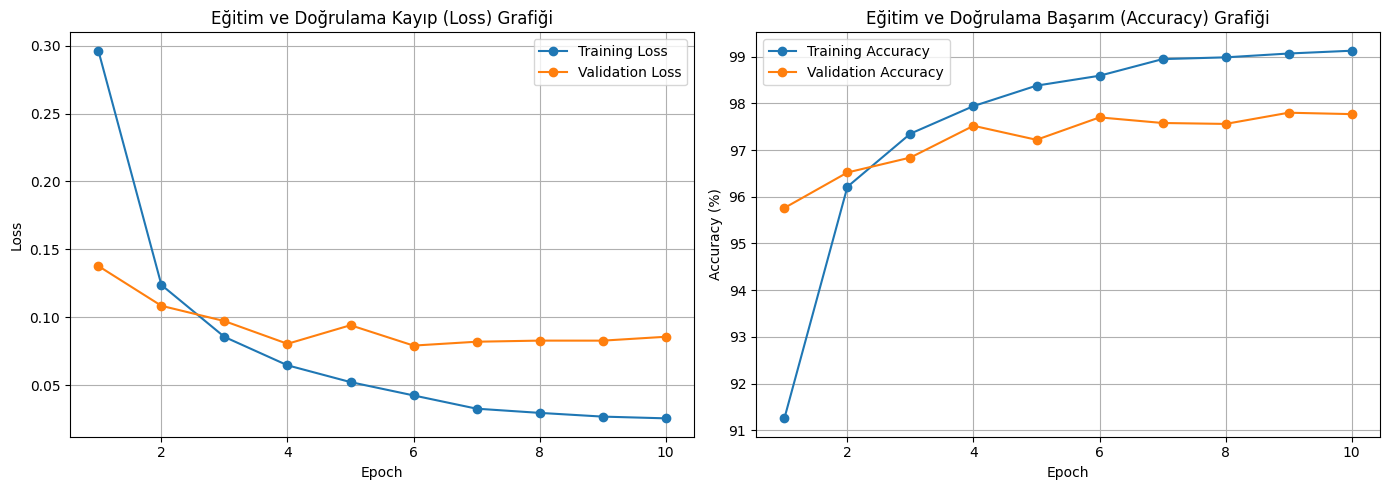

In [ ]:
# 1. Eğitim ve Değerlendirme Döngüsü
epochs = 10
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [], 'val_acc': []
}

start_time = time.time()  # Süre ölçümü başlatılıyor

for epoch in range(epochs):
    # --- EĞİTİM (TRAINING) ---
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        optimizer.zero_grad()               # Gradyanları sıfırla
        outputs = model(images)            # İleri besleme (Forward)
        loss = criterion(outputs, labels)  # Loss hesapla
        loss.backward()                    # Geriye yayılım (Backprop)
        optimizer.step()                   # Ağırlıkları güncelle

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train

    # --- DOĞRULAMA (VALIDATION) ---
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad(): # Gradyan hesaplamasını kapat (Hız ve hafıza tasarrufu)
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += (preds == labels).sum().item()
            total_val += labels.size(0)

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val

    # Metrikleri kaydet
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_acc'].append(epoch_val_acc)

    print(f"Epoch [{epoch+1:02d}/{epochs}] | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: %{epoch_train_acc*100:.2f} | "
          f"Val Loss: {epoch_val_loss:.4f} - Val Acc: %{epoch_val_acc*100:.2f}")

end_time = time.time()
training_time = end_time - start_time
print(f"\n---> Toplam Eğitim Süresi: {training_time:.2f} saniye <---")

# 2. TEST VERİ KÜMESİ İLE FİNAL DEĞERLENDİRMESİ
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        test_correct += (preds == labels).sum().item()
        test_total += labels.size(0)

test_acc = test_correct / test_total
print(f"---> Final Test Accuracy: %{test_acc*100:.2f} <---")

# 3. LOSS VE ACCURACY GRAFİKLERİ
plt.figure(figsize=(14, 5))

# Loss Grafiği
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), history['train_loss'], label='Training Loss', marker='o')
plt.plot(range(1, epochs+1), history['val_loss'], label='Validation Loss', marker='o')
plt.title('Eğitim ve Doğrulama Kayıp (Loss) Grafiği')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

# Accuracy Grafiği
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), [acc * 100 for acc in history['train_acc']], label='Training Accuracy', marker='o')
plt.plot(range(1, epochs+1), [acc * 100 for acc in history['val_acc']], label='Validation Accuracy', marker='o')
plt.title('Eğitim ve Doğrulama Başarım (Accuracy) Grafiği')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

--- KENDİ EL YAZINIZLA YAZILAN RAKAMLARIN TAHMİNLERİ ---
İşlenen Dosya: 0.jpeg


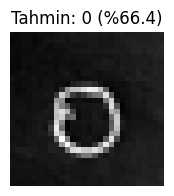

İşlenen Dosya: 1.jpeg


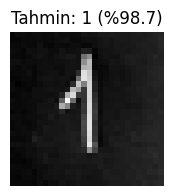

İşlenen Dosya: 2.jpeg


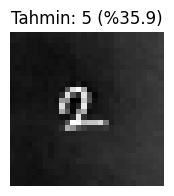

İşlenen Dosya: 4.jpeg


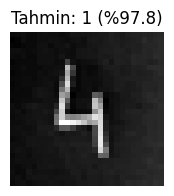

İşlenen Dosya: 5.jpeg


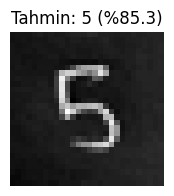

İşlenen Dosya: 6.jpeg


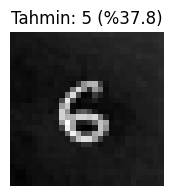

In [ ]:
import PIL.Image as Image
import PIL.ImageOps as ImageOps
import glob
import os

def predict_custom_digit(image_path, model):
    # 1. Görseli aç ve gri tonlamaya (Grayscale) dönüştür
    img = Image.open(image_path).convert('L')

    # 2. Renkleri tersine çevir (MNIST formatına uyum: Siyah zemin üzerine beyaz rakam)
    img = ImageOps.invert(img)

    # 3. 28x28 boyutuna getir
    img = img.resize((28, 28))

    # 4. Normalizasyon ve Tensor Dönüşümü
    img_tensor = transforms.ToTensor()(img)
    img_tensor = transforms.Normalize((0.1307,), (0.3081,))(img_tensor)
    img_tensor = img_tensor.unsqueeze(0)  # Batch boyutu ekleme: (1, 1, 28, 28)

    # 5. Model Tahmini
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        probabilities = torch.softmax(output, dim=1)
        pred_class = torch.argmax(probabilities, dim=1).item()
        confidence = probabilities[0][pred_class].item() * 100

    # Görselleştirme
    plt.figure(figsize=(2, 2))
    plt.imshow(img, cmap='gray')
    plt.title(f"Tahmin: {pred_class} (%{confidence:.1f})")
    plt.axis('off')
    plt.show()

    return pred_class

# Yüklenen tüm .jpg veya .png dosyalarını bulur ve tahmin eder
custom_files = sorted(glob.glob("*.jpg") + glob.glob("*.png") + glob.glob("*.jpeg"))

if custom_files:
    print("--- KENDİ EL YAZINIZLA YAZILAN RAKAMLARIN TAHMİNLERİ ---")
    for file_path in custom_files:
        print(f"İşlenen Dosya: {file_path}")
        predict_custom_digit(file_path, model)
else:
    print("Lütfen Colab'in sol menüsündeki dosya (folder) bölümüne el yazısı fotoğraflarınızı yükleyin!")

## DENEY VE DEĞERLENDİRME RAPORU

### 1. Hiperparametreler ve Model Yapısı
- **Model:** Multi-Layer Perceptron (MLP) (CNN kullanılmamıştır)
- **Katmanlar:** 784 (Girdi) -> 128 (ReLU) -> 64 (ReLU) -> 10 (Çıktı)
- **Loss Fonksiyonu:** Cross-Entropy Loss
- **Optimizer:** Adam (Learning Rate = 0.001)
- **Batch Size:** 64
- **Epoch Sayısı:** 10

### 2. Performans Sonuçları
- **Eğitim Süresi:** 164.60 saniye
- **Final Training Accuracy:** %99.13
- **Final Validation Accuracy:** %97.77
- **Final Test Accuracy:** %97.45

### 3. Kendi El Yazısı Görsellerinin Değerlendirilmesi & Dağılım Kayması (Distribution Shift)
Eğitilen model MNIST test veri setinde %97.45 başarım gösterirken, kendi el yazımızla hazırladığımız rakamlarda başarım oranında farklılıklar gözlemlenebilir.

**Nedenleri (Distribution Shift / Generalization):**
1. **Çizgi Kalınlığı ve Yoğunluk:** MNIST veri setindeki görüntüler belirli bir çizgi kalınlığı ve pürüzsüzleştirme standartlarına sahiptir.
2. **Merkezleme (Centering):** MNIST verileri rakamların ağırlık merkezine göre ortalanmıştır. Elle kırpılan fotoğraflardaki milimetrik kaymalar MLP modelinin tahmin başarısını etkileyebilir.
3. **Arka Plan Gürültüsü:** Telefon kamerası çekimlerindeki gölgeler ve ışık farklılıkları tam pürüzsüz siyah zemin elde edilmesini zorlaştırabilir.